# Clase 1 — Prophet básico: ventas de cerveza, vino y licor

Datos: `Data/BeerWineLiquor.csv` — ventas mensuales en tiendas de cerveza, vino y licor de EE. UU. (millones de dólares), de enero 1992 a **agosto 2026** (datos actualizados de FRED, serie MRTSSM4453USN).

Objetivo: pronosticar los próximos **24 meses** con Prophet.

> En el video: `from fbprophet import Prophet`. Hoy: `from prophet import Prophet`.

## Paso 1: Importar las librerías

In [1]:
import pandas as pd
from prophet import Prophet         # en el video: from fbprophet import Prophet

## Paso 2: Leer los datos

In [2]:
df = pd.read_csv('Data/BeerWineLiquor.csv')
df.head()

,observation_date,MRTSSM4453USN
0,1992-01-01,1414
1,1992-02-01,1444
2,1992-03-01,1496
3,1992-04-01,1569
4,1992-05-01,1707


## Paso 3: Revisar los tipos de datos

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 416 entries, 0 to 415
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   observation_date  416 non-null    str  
 1   MRTSSM4453USN     416 non-null    int64
dtypes: int64(1), str(1)
memory usage: 6.6 KB


## Paso 4: Renombrar las columnas a `ds` y `y` (obligatorio)

In [4]:
df.columns = ['ds', 'y']
df.head()

,ds,y
0,1992-01-01,1414
1,1992-02-01,1444
2,1992-03-01,1496
3,1992-04-01,1569
4,1992-05-01,1707


## Paso 5: Convertir la fecha en fecha de verdad

In [5]:
df['ds'] = pd.to_datetime(df['ds'])
df.head()

,ds,y
0,1992-01-01,1414
1,1992-02-01,1444
2,1992-03-01,1496
3,1992-04-01,1569
4,1992-05-01,1707


## Paso 6: Confirmar que quedó bien

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 416 entries, 0 to 415
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ds      416 non-null    datetime64[us]
 1   y       416 non-null    int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 6.6 KB


## Paso 7: Crear y entrenar el modelo

In [7]:
m = Prophet()
m.fit(df)

22:59:23 - cmdstanpy - INFO - Chain [1] start processing


22:59:23 - cmdstanpy - INFO - Chain [1] done processing


## Paso 8: Crear la tabla del futuro (24 meses)

In [8]:
future = m.make_future_dataframe(periods=24, freq='MS')   # MS = Month Start
future.head()

,ds
0,1992-01-01
1,1992-02-01
2,1992-03-01
3,1992-04-01
4,1992-05-01


In [9]:
future.tail()

,ds
435,2028-04-01
436,2028-05-01
437,2028-06-01
438,2028-07-01
439,2028-08-01


## Paso 9: Comprobar que se agregaron los 24 meses

In [10]:
df.tail()

,ds,y
411,2026-04-01,5344
412,2026-05-01,5967
413,2026-06-01,5835
414,2026-07-01,6096
415,2026-08-01,5637


In [11]:
len(df)

416

In [12]:
len(future)

440

## Paso 10: Hacer la predicción

In [13]:
forecast = m.predict(future)
forecast.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,1992-01-01,1607.930338,746.278730,1376.859995,1607.930338,1607.930338,-551.001151,-551.001151,-551.001151,-551.001151,-551.001151,-551.001151,0.0,0.0,0.0,1056.929188
1,1992-02-01,1612.888521,820.867110,1444.919228,1612.888521,1612.888521,-489.135427,-489.135427,-489.135427,-489.135427,-489.135427,-489.135427,0.0,0.0,0.0,1123.753093
2,1992-03-01,1617.526820,1112.697702,1742.520283,1617.526820,1617.526820,-180.465526,-180.465526,-180.465526,-180.465526,-180.465526,-180.465526,0.0,0.0,0.0,1437.061294
3,1992-04-01,1622.485002,1080.384979,1685.676154,1622.485002,1622.485002,-244.518988,-244.518988,-244.518988,-244.518988,-244.518988,-244.518988,0.0,0.0,0.0,1377.966014
4,1992-05-01,1627.283243,1426.946629,2010.297200,1627.283243,1627.283243,88.781081,88.781081,88.781081,88.781081,88.781081,88.781081,0.0,0.0,0.0,1716.064325


## Paso 11: Ver solo las columnas importantes

In [14]:
forecast.columns

Index(['ds', 'trend', 'yhat_lower', 'yhat_upper', 'trend_lower', 'trend_upper',
       'additive_terms', 'additive_terms_lower', 'additive_terms_upper',
       'yearly', 'yearly_lower', 'yearly_upper', 'multiplicative_terms',
       'multiplicative_terms_lower', 'multiplicative_terms_upper', 'yhat'],
      dtype='str')

In [15]:
forecast[['ds', 'yhat_lower', 'yhat_upper', 'yhat']].tail(12)

,ds,yhat_lower,yhat_upper,yhat
428,2027-09-01,5904.137067,6560.738744,6235.168595
429,2027-10-01,5998.887237,6611.932922,6300.934657
430,2027-11-01,6129.371921,6775.785280,6441.873380
431,2027-12-01,7275.363687,7895.956368,7585.445785
432,2028-01-01,5555.013021,6182.678123,5866.243740
433,2028-02-01,5620.398074,6266.165133,5941.883264
434,2028-03-01,5944.861748,6558.227882,6263.438334
435,2028-04-01,5894.332065,6514.135901,6213.158673
436,2028-05-01,6244.917463,6879.134407,6559.788227
437,2028-06-01,6205.488023,6806.167653,6499.866447


## Paso 12: Graficar con Prophet

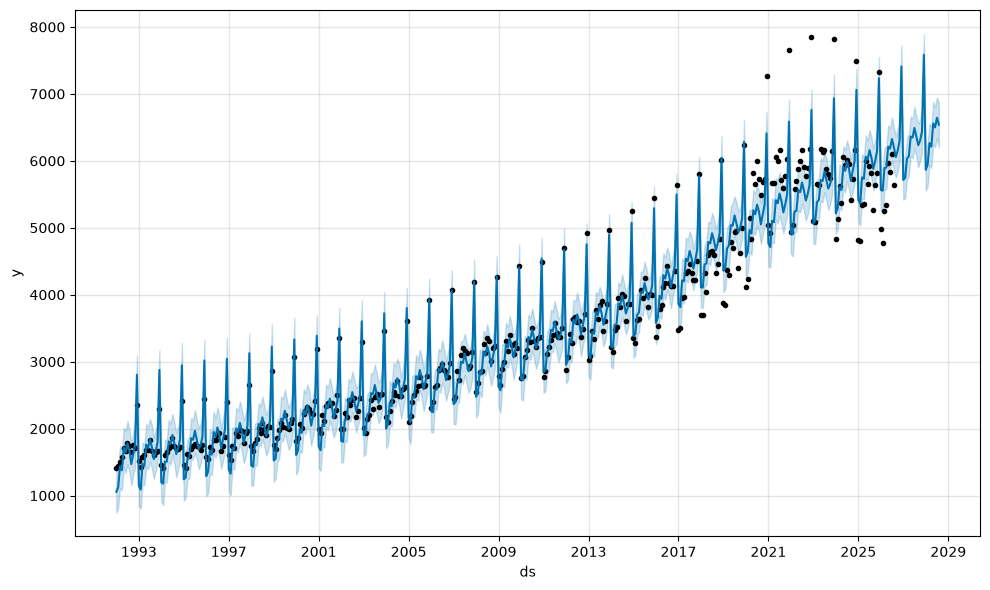

In [16]:
%matplotlib inline
m.plot(forecast);

## Paso 13: Zoom al gráfico (2019 – 2029)

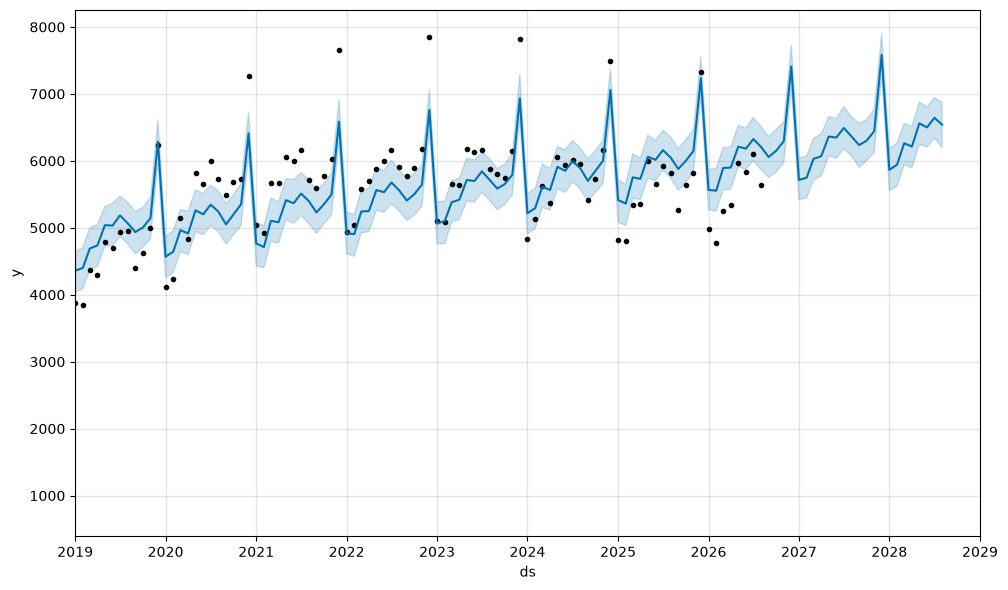

In [17]:
import matplotlib.pyplot as plt

m.plot(forecast)
plt.xlim(pd.Timestamp('2019-01-01'), pd.Timestamp('2029-01-01'));   # en el video: plt.xlim('2014-01-01', '2021-01-01')

## Paso 13b: Graficar por tu cuenta (sin la función de Prophet)

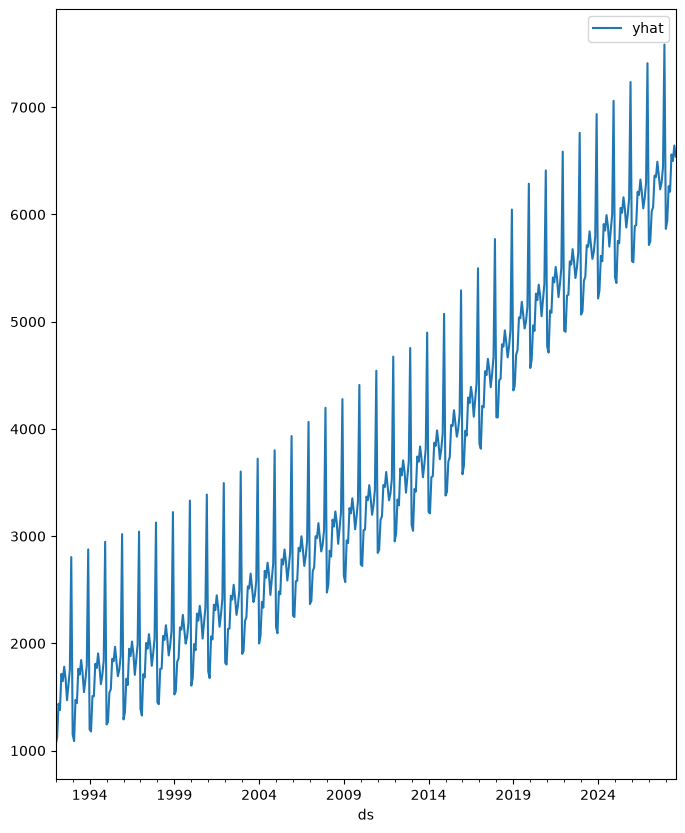

In [18]:
forecast.plot(x='ds', y='yhat', figsize=(8, 10));

## Paso 14: Ver las piezas del modelo

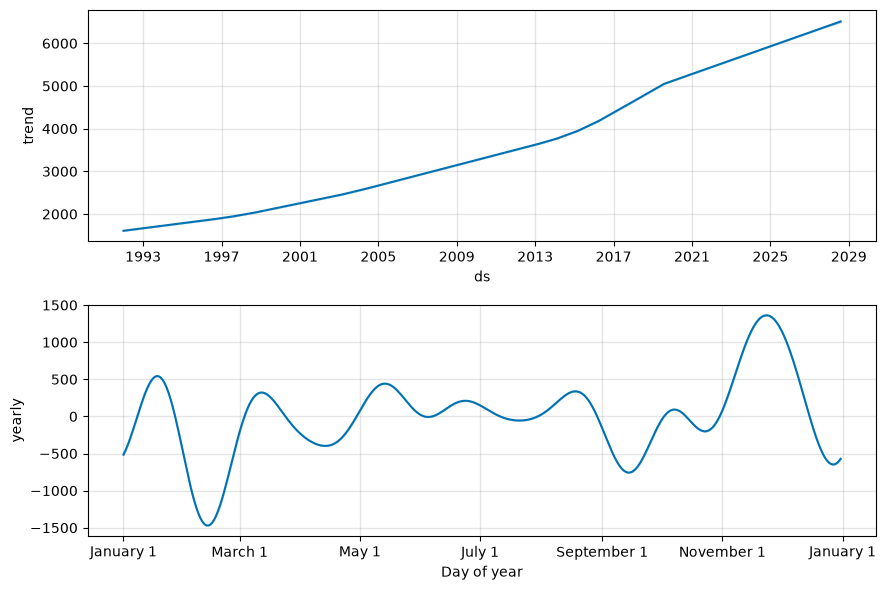

In [19]:
m.plot_components(forecast);

## Resumen

```python
df.columns = ['ds', 'y']                                   # 1. nombres obligatorios
df['ds'] = pd.to_datetime(df['ds'])                        # 2. fecha real
m = Prophet(); m.fit(df)                                   # 3. entrenar
future = m.make_future_dataframe(periods=24, freq='MS')    # 4. molde del futuro
forecast = m.predict(future)                               # 5. predecir
m.plot(forecast); m.plot_components(forecast)              # 6. graficar
```